# Clasificación de alojamientos de Airbnb en San Francisco
**Responsable:** Sofía Arango

## 1. Entorno de trabajo

In [0]:
%pip install tensorflow

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
import mlflow
import tensorflow as tf

print("MLflow:", mlflow.__version__)
print("TensorFlow:", tf.__version__)

MLflow: 3.12.0
TensorFlow: 2.21.0


In [0]:
import sys
from pathlib import Path
import pandas as pd

print("Python:", sys.version)
print("Carpeta de trabajo:", Path.cwd())
print("Pandas:", pd.__version__)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Carpeta de trabajo: /Workspace/Users/s.arango112@uniandes.edu.co
Pandas: 2.3.3


## 2. Carga de los datos

Cargamos los archivos train.csv y test.csv generados en la etapa
de ingeniería de datos. Conservamos su separación original.

In [0]:
train = pd.read_csv(
    "/Workspace/Users/s.arango112@uniandes.edu.co/train.csv"
)

test = pd.read_csv(
    "/Workspace/Users/s.arango112@uniandes.edu.co/test.csv"
)

print("Entrenamiento — filas y columnas:", train.shape)
print("Prueba — filas y columnas:", test.shape)

Entrenamiento — filas y columnas: (4482, 84)
Prueba — filas y columnas: (1120, 84)


## 3. Verificación de los datos

Comprobamos los datos faltantes, los identificadores duplicados,
la coincidencia de columnas y la separación entre entrenamiento y prueba.

In [0]:
print("Datos faltantes:")
print("Entrenamiento:", train.isna().sum().sum())
print("Prueba:", test.isna().sum().sum())

print("\nIdentificadores duplicados:")
print("Entrenamiento:", train["id"].duplicated().sum())
print("Prueba:", test["id"].duplicated().sum())

print("\n¿Tienen las mismas columnas y en el mismo orden?")
print(train.columns.equals(test.columns))

print("\n¿Hay anuncios compartidos entre entrenamiento y prueba?")
print(train["id"].isin(test["id"]).any())

Datos faltantes:
Entrenamiento: 0
Prueba: 0

Identificadores duplicados:
Entrenamiento: 0
Prueba: 0

¿Tienen las mismas columnas y en el mismo orden?
True

¿Hay anuncios compartidos entre entrenamiento y prueba?
False


## 4. Selección de alojamientos evaluables

El equipo definió que se necesitan al menos cinco reseñas para evaluar
un alojamiento. Por eso conservamos únicamente los anuncios con
can_evaluate = 1.

Dentro de este grupo, recommended = 1 indica una calificación general
de 4,9 o más, y recommended = 0 indica una calificación inferior.

In [0]:
# Crear copias con los anuncios que tienen suficientes reseñas
train_clasif = train.loc[train["can_evaluate"] == 1].copy()
test_clasif = test.loc[test["can_evaluate"] == 1].copy()

print("Anuncios de entrenamiento evaluables:", len(train_clasif))
print("Anuncios de prueba evaluables:", len(test_clasif))

# Examinar la distribución de clases solo en entrenamiento
conteos = (
    train_clasif["recommended"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

resumen_clases = pd.DataFrame({
    "Cantidad": conteos,
    "Porcentaje": conteos / len(train_clasif) * 100
})

resumen_clases.index = ["No recomendado", "Recomendado"]

display(resumen_clases.round(2))

Anuncios de entrenamiento evaluables: 2867
Anuncios de prueba evaluables: 702


Cantidad,Porcentaje
1532,53.44
1335,46.56


## 5. Definición de las variables predictoras

Definimos tres conjuntos de variables para comparar qué información
ayuda a distinguir los alojamientos recomendados:

- A: características físicas, ubicación y servicios del alojamiento.
- B: conjunto A más precio e información del anfitrión.
- C: conjunto B más número de reseñas y frecuencia mensual de reseñas.

La comparación de estos conjuntos se presenta en la sección de
experimentos preliminares, utilizando ROC-AUC de validación.

Excluimos las calificaciones porque la calificación general define
la etiqueta recommended. También excluimos identificadores,
indicadores de selección y host_is_superhost, este último por su
relación con las evaluaciones de huéspedes.

La variable que queremos predecir es recommended. El análisis se
limita a alojamientos con al menos cinco reseñas.

In [0]:
# Características de la propiedad y sus servicios
variables_base = [
    "latitude", "longitude", "accommodates",
    "bedrooms", "beds", "bathrooms", "shared_bath",
    "minimum_nights", "n_amenities",
    "wifi", "kitchen", "parking", "washer",
    "air_conditioning", "workspace"
]

# Categorías que ya se convirtió en columnas de 0 y 1
variables_dummy = [
    columna for columna in train_clasif.columns
    if columna.startswith((
        "room_type_",
        "property_type_",
        "neighbourhood_cleansed_"
    ))
]

variables_A = variables_base + variables_dummy

variables_B = variables_A + [
    "log_price",
    "host_identity_verified",
    "hosts_time_as_host_years",
    "host_listings_count"
]

variables_C = variables_B + [
    "number_of_reviews",
    "reviews_per_month"
]

conjuntos_variables = {
    "A_propiedad": variables_A,
    "B_propiedad_anfitrion": variables_B,
    "C_con_historial": variables_C
}

# Tabla con todas las entradas candidatas y respuesta por separado
X_desarrollo = train_clasif[variables_C].astype("float32").copy()
y_desarrollo = train_clasif["recommended"].astype(int).copy()

for nombre, columnas in conjuntos_variables.items():
    print(f"{nombre}: {len(columnas)} variables")

print("\nEntradas disponibles:", X_desarrollo.shape)
print("Respuestas:", y_desarrollo.shape)

A_propiedad: 61 variables
B_propiedad_anfitrion: 65 variables
C_con_historial: 67 variables

Entradas disponibles: (2867, 67)
Respuestas: (2867,)


## 6. Separación de entrenamiento, validación y prueba

Conservamos la separación de entrenamiento y prueba realizada en
ingeniería de datos. Del entrenamiento reservamos un 20 % para
validación.

Entrenamiento permite ajustar los pesos de la red.
Utilizamos validación para comparar las arquitecturas y seleccionar el umbral de clasificación.
Prueba se reserva para evaluar el modelo seleccionado.

El conjunto de prueba ya fue consultado en experimentos preliminares;
esta limitación se tendrá en cuenta al reportar los resultados.

In [0]:
from sklearn.model_selection import train_test_split

SEMILLA = 42

# Dividir únicamente los datos de desarrollo
X_entrena, X_val, y_entrena, y_val = train_test_split(
    X_desarrollo,
    y_desarrollo,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y_desarrollo
)

# Preparar por separado los datos de prueba
X_test = test_clasif[variables_C].astype("float32").copy()
y_test = test_clasif["recommended"].astype(int).copy()

print("Entrenamiento:", X_entrena.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (2293, 67)
Validación: (574, 67)
Prueba: (702, 67)


## 7. Herramientas para construir la red neuronal

Utilizamos TensorFlow y Keras, siguiendo el ejemplo de clasificación
trabajado en clase. Fijamos una semilla para facilitar la reproducción
de los experimentos.

In [0]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

keras.utils.set_random_seed(SEMILLA)

print("TensorFlow:", tf.__version__)
print("Semilla:", SEMILLA)

TensorFlow: 2.21.0
Semilla: 42


## 8. Preparación de los datasets de TensorFlow

Creamos una función que empareja las características de cada
alojamiento con su etiqueta y organiza los ejemplos en lotes de 32.
Solo mezclamos el orden de los datos de entrenamiento.

In [0]:
def dataframe_to_dataset(X, y, nombres, mezclar=False):
    # Preparar las características con los nombres de entrada de Keras
    caracteristicas = {
        nombres[columna]: X[columna].to_numpy(
            dtype="float32"
        ).reshape(-1, 1)
        for columna in X.columns
    }

    # Respuesta de cada alojamiento: 0 o 1
    etiquetas = y.to_numpy(dtype="float32")

    # Emparejar las características y sus respuestas
    ds = tf.data.Dataset.from_tensor_slices(
        (caracteristicas, etiquetas)
    )

    # Mezclar únicamente cuando lo indiquemos
    if mezclar:
        ds = ds.shuffle(
            buffer_size=len(X),
            seed=SEMILLA
        )

    return ds.batch(32)

## 9. Creación de los datasets

Preparamos los datasets con el conjunto C, que contiene las 67 variables candidatas. Asignamos un nombre interno a cada entrada de Keras. En la sección 11.1 usamos los subconjuntos A, B y C para comparar su desempeño en los mismos alojamientos de validación.

In [0]:
# Columnas que recibirá el modelo
variables_modelo = variables_C.copy()

# Relacionar los nombres originales con nombres internos sencillos
nombres_keras = {
    columna: f"variable_{i}"
    for i, columna in enumerate(variables_modelo)
}

# Crear los datasets
train_ds = dataframe_to_dataset(
    X_entrena[variables_modelo],
    y_entrena,
    nombres_keras,
    mezclar=True
)

val_ds = dataframe_to_dataset(
    X_val[variables_modelo],
    y_val,
    nombres_keras
)

test_ds = dataframe_to_dataset(
    X_test[variables_modelo],
    y_test,
    nombres_keras
)

print("Características por alojamiento:", len(variables_modelo))
print("Lotes de entrenamiento:", int(train_ds.cardinality().numpy()))
print("Lotes de validación:", int(val_ds.cardinality().numpy()))
print("Lotes de prueba:", int(test_ds.cardinality().numpy()))

Características por alojamiento: 67
Lotes de entrenamiento: 72
Lotes de validación: 18
Lotes de prueba: 22


## 10. Normalización de las variables numéricas

Las variables numéricas tienen escalas diferentes. Utilizamos capas
Normalization de Keras para restar su media y dividir por su
desviación estándar.

Estas estadísticas se calculan únicamente con entrenamiento.
Los indicadores de sí/no y las variables dummy conservan sus valores
de 0 y 1.

In [0]:
# Variables numéricas que normalizaremos
columnas_normalizar = [
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms",
    "minimum_nights",
    "n_amenities",
    "log_price",
    "hosts_time_as_host_years",
    "host_listings_count",
    "number_of_reviews",
    "reviews_per_month"
]

# Función para crear una normalización por variable
def encode_numerical_feature(entrada, valores_entrenamiento):
    normalizador = keras.layers.Normalization(axis=None)

    normalizador.adapt(valores_entrenamiento)

    return normalizador(entrada)

## 11. Entradas y preparación de las características

Creamos una entrada por característica. Las variables numéricas pasan
por una capa de normalización calculada con entrenamiento; los
indicadores y las dummies pasan directamente.

Finalmente unimos las 67 características para conectarlas a la red.

In [0]:
inputs = {}
feats_encoded = []

for columna in variables_modelo:
    nombre = nombres_keras[columna]

    # Una entrada recibe un valor por alojamiento
    entrada = keras.Input(
        shape=(1,),
        name=nombre,
        dtype="float32"
    )

    inputs[nombre] = entrada

    if columna in columnas_normalizar:
        valores = X_entrena[[columna]].to_numpy(dtype="float32")

        entrada_preparada = encode_numerical_feature(
            entrada,
            valores
        )
    else:
        entrada_preparada = entrada

    feats_encoded.append(entrada_preparada)

# Unir todas las características
all_feats = keras.layers.Concatenate(
    name="caracteristicas_unidas"
)(feats_encoded)

print("Entradas creadas:", len(inputs))
print("Variables normalizadas:", len(columnas_normalizar))
print("Forma de las características unidas:", all_feats.shape)

Entradas creadas: 67
Variables normalizadas: 13
Forma de las características unidas: (None, 67)


## 11.1. Comparación de conjuntos de variables

Comparamos A, B y C utilizando una red de 32 neuronas,
Adam y 50 épocas. Evaluamos mediante ROC-AUC de validación.

In [0]:
from sklearn.metrics import roc_auc_score

# Recuperar las características que ya preparamos y normalizamos
caracteristicas_preparadas = dict(zip(variables_modelo, feats_encoded))

resultados_variables = []

for nombre, columnas in conjuntos_variables.items():
    keras.utils.set_random_seed(SEMILLA)

    # Seleccionar las entradas correspondientes a este conjunto
    entradas = {
        nombres_keras[columna]: inputs[nombres_keras[columna]]
        for columna in columnas
    }

    caracteristicas = [
        caracteristicas_preparadas[columna]
        for columna in columnas
    ]

    # Construir la misma arquitectura para los tres conjuntos
    unidas = keras.layers.Concatenate()(caracteristicas)
    oculta = keras.layers.Dense(32, activation="relu")(unidas)
    salida = keras.layers.Dense(1, activation="sigmoid")(oculta)

    red_comparacion = keras.Model(inputs=entradas, outputs=salida)
    red_comparacion.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # Preparar los mismos anuncios con las columnas seleccionadas
    ds_entrena = dataframe_to_dataset(
        X_entrena[columnas], y_entrena, nombres_keras, mezclar=True
    )
    ds_val = dataframe_to_dataset(
        X_val[columnas], y_val, nombres_keras
    )

    red_comparacion.fit(ds_entrena, epochs=50, verbose=0)

    probabilidades = red_comparacion.predict(ds_val, verbose=0).ravel()
    auc = roc_auc_score(y_val, probabilidades)

    resultados_variables.append({
        "Conjunto": nombre,
        "Variables": len(columnas),
        "ROC_AUC_validacion": auc
    })

    print(f"{nombre} — ROC-AUC: {auc:.4f}")

tabla_variables = pd.DataFrame(resultados_variables)
display(tabla_variables.round(4))

/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


A_propiedad — ROC-AUC: 0.7247


/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


B_propiedad_anfitrion — ROC-AUC: 0.7466


/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C_con_historial — ROC-AUC: 0.7741


Conjunto,Variables,ROC_AUC_validacion
A_propiedad,61,0.7247
B_propiedad_anfitrion,65,0.7466
C_con_historial,67,0.7741


El conjunto C obtuvo el mayor ROC-AUC de validación (0.7741).
En esta comparación, incorporar precio, información del anfitrión
e historial de reseñas mejoró el desempeño frente a utilizar
únicamente características de la propiedad.

Seleccionamos sus 67 variables para comparar las arquitecturas.
El modelo se limita a anuncios existentes con al menos cinco reseñas.

### Configuración de MLflow

Seguimos el procedimiento de Databricks del Taller 10. Usamos un experimento con ruta absoluta y el seguimiento del workspace. Cada configuración de la búsqueda tiene su propia corrida. El registro automático de Keras guarda los parámetros y las métricas del entrenamiento. Además, registramos el ROC-AUC de validación para comparar las configuraciones.

In [0]:
import mlflow
import mlflow.keras

experimento = mlflow.set_experiment(
    "/Airbnb_SanFrancisco_Clasificacion_Sofia"
)

print("Experimento:", experimento.name)
print("Versión de MLflow:", mlflow.__version__)

Experimento: /Airbnb_SanFrancisco_Clasificacion_Sofia
Versión de MLflow: 3.12.0


## 11.2. Comparación de arquitecturas

Con el conjunto C seleccionado, comparamos redes con una capa
oculta de 16, 32 y 64 neuronas y activación ReLU. Todas tienen
una salida sigmoide.

Mantenemos los mismos datos, normalización, optimizador Adam
y 50 épocas de entrenamiento. Comparamos los resultados mediante
ROC-AUC de validación.

In [0]:
from sklearn.metrics import roc_auc_score

# Activar el registro automático de Keras, como en el taller
mlflow.keras.autolog()

resultados = []
modelos = {}
historiales = {}
corridas_arquitecturas = {}

for neuronas in [16, 32, 64]:
    keras.utils.set_random_seed(SEMILLA)

    with mlflow.start_run(
        run_name=f"red_{neuronas}_tasa_0.001"
    ) as corrida:

        oculta = keras.layers.Dense(
            neuronas, activation="relu"
        )(all_feats)

        salida = keras.layers.Dense(
            1, activation="sigmoid"
        )(oculta)

        red = keras.Model(inputs=inputs, outputs=salida)

        red.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        mlflow.log_params({
            "neuronas": neuronas,
            "tasa_aprendizaje": 0.001,
            "conjunto_variables": "C",
            "epocas": 50
        })

        historia = red.fit(
            train_ds,
            validation_data=val_ds,
            epochs=50,
            verbose=0
        )

        probabilidades = red.predict(val_ds, verbose=0).ravel()
        auc = roc_auc_score(y_val, probabilidades)

        mlflow.log_metric("roc_auc_validacion", float(auc))

        corridas_arquitecturas[neuronas] = corrida.info.run_id

    modelos[neuronas] = red
    historiales[neuronas] = historia.history

    resultados.append({
        "Neuronas": neuronas,
        "ROC_AUC_validacion": auc
    })

    print(f"{neuronas} neuronas — ROC-AUC: {auc:.4f}")

tabla_experimentos = pd.DataFrame(resultados).sort_values(
    "ROC_AUC_validacion", ascending=False
)

display(tabla_experimentos.round(4))

2026/11/25 00:22:27 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:22:27 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:22:41 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:22:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:22:42 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:22:51 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


16 neuronas — ROC-AUC: 0.7553


2026/11/25 00:22:53 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:22:53 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:23:08 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:23:08 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:23:08 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:23:16 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


32 neuronas — ROC-AUC: 0.7709


2026/11/25 00:23:18 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:23:18 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:23:33 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:23:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:23:33 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:23:41 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


64 neuronas — ROC-AUC: 0.7616


Neuronas,ROC_AUC_validacion
32,0.7709
64,0.7616
16,0.7553


## 11.3. Comparación de neuronas y tasas de aprendizaje

Con el conjunto C, comparamos 16, 32 y 64 neuronas combinadas
con tasas de aprendizaje de 0.0003, 0.001 y 0.003.

Mantenemos el optimizador Adam, 50 épocas y las mismas divisiones
de datos. Evaluamos las nueve combinaciones mediante ROC-AUC
de validación.

Reutilizamos las tres corridas de la sección 11.2 con tasa de aprendizaje de 0.001 y entrenamos las seis combinaciones restantes. En total, comparamos nueve corridas distintas mediante ROC-AUC de validación.

In [0]:
resultados_busqueda = []
modelos_busqueda = {}
historiales_busqueda = {}
corridas_busqueda = {}

for neuronas in [16, 32, 64]:
    for tasa in [0.0003, 0.001, 0.003]:

        if tasa == 0.001:
            red = modelos[neuronas]
            historia = historiales[neuronas]
            id_corrida = corridas_arquitecturas[neuronas]

        else:
            keras.utils.set_random_seed(SEMILLA)

            with mlflow.start_run(
                run_name=f"red_{neuronas}_tasa_{tasa}"
            ) as corrida:

                oculta = keras.layers.Dense(
                    neuronas, activation="relu"
                )(all_feats)

                salida = keras.layers.Dense(
                    1, activation="sigmoid"
                )(oculta)

                red = keras.Model(inputs=inputs, outputs=salida)

                red.compile(
                    optimizer=keras.optimizers.Adam(
                        learning_rate=tasa
                    ),
                    loss="binary_crossentropy",
                    metrics=["accuracy"]
                )

                mlflow.log_params({
                    "neuronas": neuronas,
                    "tasa_aprendizaje": tasa,
                    "conjunto_variables": "C",
                    "epocas": 50
                })

                entrenamiento = red.fit(
                    train_ds,
                    validation_data=val_ds,
                    epochs=50,
                    verbose=0
                )

                historia = entrenamiento.history

                probabilidades = red.predict(
                    val_ds, verbose=0
                ).ravel()

                auc = roc_auc_score(y_val, probabilidades)

                mlflow.log_metric(
                    "roc_auc_validacion", float(auc)
                )

                id_corrida = corrida.info.run_id

        probabilidades = red.predict(val_ds, verbose=0).ravel()
        auc = roc_auc_score(y_val, probabilidades)

        clave = (neuronas, tasa)
        modelos_busqueda[clave] = red
        historiales_busqueda[clave] = historia
        corridas_busqueda[clave] = id_corrida

        resultados_busqueda.append({
            "Neuronas": neuronas,
            "Tasa_aprendizaje": tasa,
            "ROC_AUC_validacion": auc
        })

        print(
            f"{neuronas} neuronas | tasa {tasa} | "
            f"ROC-AUC: {auc:.4f}"
        )

tabla_busqueda = pd.DataFrame(resultados_busqueda).sort_values(
    "ROC_AUC_validacion", ascending=False
)

display(tabla_busqueda.round(4))

2026/11/25 00:24:07 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:24:08 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:24:21 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:24:21 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:24:22 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:24:29 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


16 neuronas | tasa 0.0003 | ROC-AUC: 0.7620
16 neuronas | tasa 0.001 | ROC-AUC: 0.7553


2026/11/25 00:24:32 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:24:33 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:24:47 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:24:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:24:47 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:24:54 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


16 neuronas | tasa 0.003 | ROC-AUC: 0.7431


... (9 outputs left out)

2026/11/25 00:26:10 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
2026/11/25 00:26:10 WARNING mlflow.data.tensorflow_dataset: Failed to infer schema for TensorFlow dataset. Exception: Failed to infer schema for tf.data.Dataset. Schemas can only be inferred if the dataset consists of tensors. Ragged tensors, tensor arrays, and other types are not supported. Additionally, datasets with nested tensors are not supported.
/local_disk0/.ephemeral_nfs/envs/pythonEnv-fee48662-0867-4018-a225-97b288cd1c90/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to

2026/11/25 00:26:25 WARNING mlflow.keras.autologging: Failed to get model signature, reason: Creating Schema with multiple unnamed TensorSpecs is not supported. Please provide names for each TensorSpec.
2026/11/25 00:26:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 00:26:25 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/11/25 00:26:33 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.12.0/ml/model/signatures.html for instructions on setting signature on models.


64 neuronas | tasa 0.003 | ROC-AUC: 0.7428


Neuronas,Tasa_aprendizaje,ROC_AUC_validacion
64,3.0E-4,0.7713
32,0.001,0.7709
32,3.0E-4,0.7663
16,3.0E-4,0.762
64,0.001,0.7616
16,0.001,0.7553
16,0.003,0.7431
64,0.003,0.7428
32,0.003,0.7319


La combinación de 64 neuronas y tasa de aprendizaje de 0.0003 obtuvo el mayor ROC-AUC de validación (0.7713) entre las nueve configuraciones evaluadas, seguida por la red de 32 neuronas y tasa de 0.001 (0.7709).

## 12. Selección del modelo

Seleccionamos el conjunto C, con 67 variables, y una red con una capa oculta de 64 neuronas con activación ReLU y una salida sigmoide. La red se entrenó durante 50 épocas con Adam y una tasa de aprendizaje de 0.0003. Esta configuración obtuvo el mayor ROC-AUC de validación entre las nueve corridas de la búsqueda (0.7713).

El ROC-AUC de 0.7741 de la sección 11.1 corresponde al experimento preliminar que se utilizó para comparar los conjuntos de variables.

In [0]:
# Recuperar la mejor combinación ya entrenada
mejor = tabla_busqueda.iloc[0]

neuronas_elegidas = int(mejor["Neuronas"])
tasa_elegida = float(mejor["Tasa_aprendizaje"])

clave_elegida = (neuronas_elegidas, tasa_elegida)

modelo = modelos_busqueda[clave_elegida]
historial = historiales_busqueda[clave_elegida]

print("Neuronas seleccionadas:", neuronas_elegidas)
print("Tasa de aprendizaje:", tasa_elegida)
print("ROC-AUC de validación:", round(mejor["ROC_AUC_validacion"], 4))

Neuronas seleccionadas: 64
Tasa de aprendizaje: 0.0003
ROC-AUC de validación: 0.7713


## 13. Evolución del entrenamiento

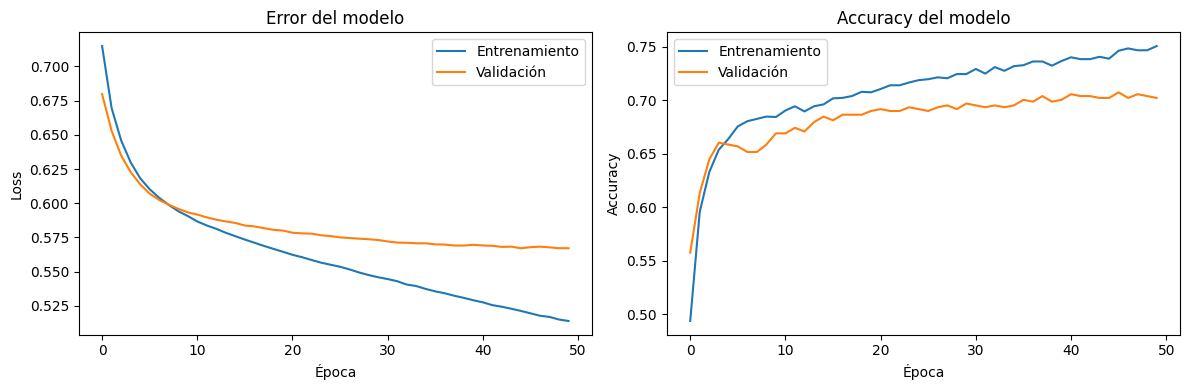

In [0]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Error durante el entrenamiento
plt.subplot(1, 2, 1)
plt.plot(historial["loss"], label="Entrenamiento")
plt.plot(historial["val_loss"], label="Validación")
plt.title("Error del modelo")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

# Proporción de clasificaciones correctas
plt.subplot(1, 2, 2)
plt.plot(historial["accuracy"], label="Entrenamiento")
plt.plot(historial["val_accuracy"], label="Validación")
plt.title("Accuracy del modelo")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Durante las primeras épocas disminuye el error y aumenta el accuracy en entrenamiento y validación. Posteriormente, el desempeño de validación se estabiliza, mientras el modelo continúa mejorando en entrenamiento. Esta diferencia indica señales de sobreajuste.

## 14. Evaluación en validación

Las métricas de esta sección se calcularon con el umbral inicial de 0.50. En la sección siguiente comparamos los umbrales candidatos en la misma muestra de validación y seleccionamos el que obtiene el mayor F1.

In [0]:
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Obtener las probabilidades de la red seleccionada
probabilidades_val = modelo.predict(val_ds, verbose=0).ravel()

# Convertir las probabilidades en decisiones
predicciones_val = (probabilidades_val >= 0.50).astype(int)

print("Resultados en validación:")
print("ROC-AUC:", round(roc_auc_score(y_val, probabilidades_val), 4))
print("Accuracy:", round(accuracy_score(y_val, predicciones_val), 4))
print("Precision:", round(precision_score(y_val, predicciones_val, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, predicciones_val, zero_division=0), 4))
print("F1:", round(f1_score(y_val, predicciones_val, zero_division=0), 4))

Resultados en validación:
ROC-AUC: 0.7713
Accuracy: 0.7021
Precision: 0.689
Recall: 0.6554
F1: 0.6718


## 15. Selección del umbral

In [0]:
resultados_umbrales = []

for umbral in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predicciones = (probabilidades_val >= umbral).astype(int)

    resultados_umbrales.append({
        "Umbral": umbral,
        "Precision": precision_score(y_val, predicciones, zero_division=0),
        "Recall": recall_score(y_val, predicciones, zero_division=0),
        "F1": f1_score(y_val, predicciones, zero_division=0)
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)
display(tabla_umbrales.round(4))

Umbral,Precision,Recall,F1
0.3,0.59,0.8839,0.7076
0.4,0.614,0.7865,0.6897
0.5,0.689,0.6554,0.6718
0.6,0.7348,0.4981,0.5938
0.7,0.8431,0.3221,0.4661


In [0]:
umbral_elegido = float(
    tabla_umbrales.loc[tabla_umbrales["F1"].idxmax(), "Umbral"]
)

print("Umbral seleccionado:", umbral_elegido)

Umbral seleccionado: 0.3


Se seleccionó el umbral de 0.30 porque obtuvo el mayor F1 en validación entre los valores evaluados: 0.7076. Con este umbral, la precision fue de 59% y el recall de 88.39 %. La arquitectura se seleccionó mediante ROC-AUC y el umbral mediante F1.

## 16. Evaluación en prueba

In [0]:
# Obtener probabilidades para los anuncios de prueba
probabilidades_test = modelo.predict(test_ds, verbose=0).ravel()

# Aplicar el umbral seleccionado en validación
predicciones_test = (
    probabilidades_test >= umbral_elegido
).astype(int)

print("Resultados en prueba:")
print("ROC-AUC:", round(roc_auc_score(y_test, probabilidades_test), 4))
print("Accuracy:", round(accuracy_score(y_test, predicciones_test), 4))
print("Precision:", round(precision_score(y_test, predicciones_test, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, predicciones_test, zero_division=0), 4))
print("F1:", round(f1_score(y_test, predicciones_test, zero_division=0), 4))

Resultados en prueba:
ROC-AUC: 0.7428
Accuracy: 0.6581
Precision: 0.616
Recall: 0.8652
F1: 0.7196


## 17. Matriz de confusión

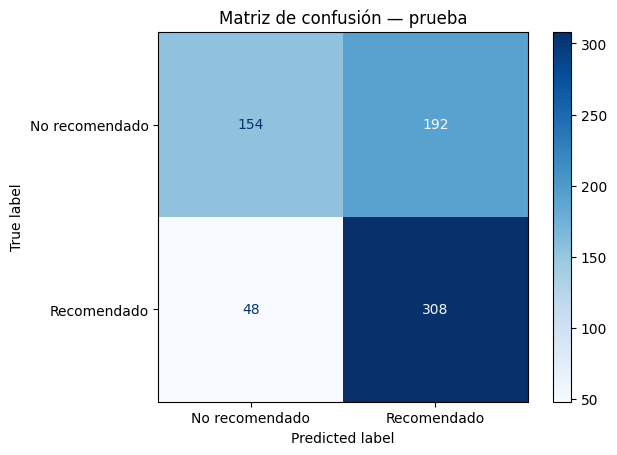

In [0]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(y_test, predicciones_test)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["No recomendado", "Recomendado"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión — prueba")
plt.show()

El modelo clasificó correctamente 462 de los 702 alojamientos de prueba (65,81 %). Identificó 308 de los 356 alojamientos realmente recomendados, alcanzando un recall de 86,52 %, y dejó de identificar 48. Sin embargo, recomendó incorrectamente 192 alojamientos, por lo que su precisión fue de 61,60 %. Estos resultados muestran que detecta una proporción alta de los alojamientos recomendados, aunque una parte considerable de sus recomendaciones corresponde a alojamientos que no cumplen el criterio definido.

## 18. Comparación con una referencia

In [0]:
# Referencia sencilla: recomendar todos los alojamientos
predicciones_referencia = np.ones(len(y_test), dtype=int)

comparacion = pd.DataFrame({
    "Modelo": ["Recomendar todos", "Red neuronal"],
    "Precision": [
        precision_score(y_test, predicciones_referencia),
        precision_score(y_test, predicciones_test)
    ],
    "Recall": [
        recall_score(y_test, predicciones_referencia),
        recall_score(y_test, predicciones_test)
    ],
    "F1": [
        f1_score(y_test, predicciones_referencia),
        f1_score(y_test, predicciones_test)
    ]
})

display(comparacion.round(4))

Modelo,Precision,Recall,F1
Recomendar todos,0.5071,1.0,0.673
Red neuronal,0.616,0.8652,0.7196


Frente a la estrategia de recomendar todos los alojamientos, la red neuronal aumentó la precisión de 50.71 % a 61.60 % y el F1 de 0.6730 a 0.7196. El recall bajó de 100 % a 86.52 %. La red hizo 154 recomendaciones incorrectas menos y dejó de identificar 48 alojamientos recomendados.

## 19. Guardado del modelo y su configuración

In [0]:
modelo.save("modelo_clasificacion.keras")

print("Modelo guardado.")

Modelo guardado.


In [0]:
import json

configuracion = {
    "variables": variables_modelo,
    "nombres_keras": nombres_keras,
    "umbral": umbral_elegido,
    "neuronas": neuronas_elegidas,
    "tasa_aprendizaje": tasa_elegida
}

with open("configuracion_clasificacion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=4)

print("Configuración guardada.")

Configuración guardada.


## 20. Registro de experimentos en MLflow

Registramos las corridas durante el entrenamiento. En esta sección consultamos los resultados y añadimos el umbral, las métricas de prueba y los archivos a la corrida del modelo seleccionado. La exportación reúne nueve corridas distintas en Databricks.

In [0]:
import mlflow

print("Versión de MLflow:", mlflow.__version__)

Versión de MLflow: 3.12.0


### 20.2. Consulta de los experimentos registrados

Consultamos las corridas del experimento y las ordenamos de mayor
a menor ROC-AUC de validación para comparar sus resultados.

In [0]:
corridas = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    order_by=["metrics.roc_auc_validacion DESC"]
)

ids_actuales = list(corridas_busqueda.values())

corridas = corridas[
    corridas["run_id"].isin(ids_actuales)
].copy()

print("Número de corridas registradas:", len(corridas))

columnas = [
    "params.neuronas",
    "params.tasa_aprendizaje",
    "metrics.roc_auc_validacion"
]

if not corridas.empty:
    display(corridas[columnas])

Número de corridas registradas: 9


params.neuronas,params.tasa_aprendizaje,metrics.roc_auc_validacion
64,0.0003,0.7713037855774745
32,0.001,0.7709133940880089
32,0.0003,0.7662774951506057
16,0.0003,0.7619587892983934
64,0.001,0.7615805975429736
16,0.001,0.7553465334455709
16,0.003,0.7430980004635899
64,0.003,0.7427808073783992
32,0.003,0.731935243811685


### 20.3. Identificación del modelo seleccionado

Seleccionamos la corrida con mayor ROC-AUC de validación y
la marcamos en MLflow. Los resultados de prueba no intervienen
en esta selección.

In [0]:
id_mejor_corrida = corridas_busqueda[clave_elegida]

with mlflow.start_run(run_id=id_mejor_corrida):
    mlflow.set_tag("modelo_seleccionado", "si")

print("ID de la corrida seleccionada:", id_mejor_corrida)
print("Neuronas:", neuronas_elegidas)
print("Tasa de aprendizaje:", tasa_elegida)
print(
    "ROC-AUC de validación:",
    round(float(mejor["ROC_AUC_validacion"]), 4)
)

ID de la corrida seleccionada: 5eb1f89e4959473ab0eab779e09c6703
Neuronas: 64
Tasa de aprendizaje: 0.0003
ROC-AUC de validación: 0.7713


### 20.4. Registro de los resultados de prueba

Añadimos a la corrida seleccionada el umbral elegido en validación
y las métricas obtenidas en prueba.

In [0]:
metricas_prueba = {
    "roc_auc_prueba": roc_auc_score(y_test, probabilidades_test),
    "accuracy_prueba": accuracy_score(y_test, predicciones_test),
    "precision_prueba": precision_score(
        y_test, predicciones_test, zero_division=0
    ),
    "recall_prueba": recall_score(
        y_test, predicciones_test, zero_division=0
    ),
    "f1_prueba": f1_score(
        y_test, predicciones_test, zero_division=0
    )
}

with mlflow.start_run(run_id=id_mejor_corrida):
    mlflow.log_param("umbral", umbral_elegido)
    mlflow.log_metrics(metricas_prueba)

print("Umbral registrado:", umbral_elegido)

for nombre, valor in metricas_prueba.items():
    print(f"{nombre}: {valor:.4f}")

Umbral registrado: 0.3
roc_auc_prueba: 0.7428
accuracy_prueba: 0.6581
precision_prueba: 0.6160
recall_prueba: 0.8652
f1_prueba: 0.7196


### 20.5. Guardado de archivos en MLflow

Adjuntamos el modelo entrenado (modelo_clasificacion.keras) y su configuración (configuracion_clasificacion.json) a la corrida seleccionada en MLflow.

Las salidas de MLflow indican que el registro automático guardó el modelo sin una firma de entrada. El archivo JSON adjunto documenta las 67 variables, sus nombres de entrada en Keras y el umbral de clasificación.

In [0]:
with mlflow.start_run(run_id=id_mejor_corrida):
    mlflow.log_artifact("modelo_clasificacion.keras")
    mlflow.log_artifact("configuracion_clasificacion.json")

# Consultar los archivos asociados a la corrida
cliente = mlflow.tracking.MlflowClient()
archivos_guardados = cliente.list_artifacts(id_mejor_corrida)

print("Archivos guardados en la corrida:")
for archivo in archivos_guardados:
    print(archivo.path)

Archivos guardados en la corrida:
configuracion_clasificacion.json
model_summary.txt
modelo_clasificacion.keras


### 20.6. Exportación de los resultados

Exportamos las corridas de MLflow y las tablas de comparación a la carpeta de soportes del workspace de Databricks.

In [0]:
from pathlib import Path

carpeta_mlflow = (
    Path("/Workspace/Users/s.arango112@uniandes.edu.co")
    / "soportes_clasificacion"
)
carpeta_mlflow.mkdir(exist_ok=True)

# Consultar los registros actualizados, incluidas las métricas de prueba
corridas = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    order_by=["metrics.roc_auc_validacion DESC"]
)

ids_actuales = list(corridas_busqueda.values())

corridas = corridas[
    corridas["run_id"].isin(ids_actuales)
].copy()

# Guardar las tablas en la carpeta de soportes
corridas.to_csv(carpeta_mlflow / "corridas_mlflow.csv", index=False)

tabla_variables.to_csv(
    carpeta_mlflow / "comparacion_variables.csv", index=False
)

tabla_busqueda.to_csv(
    carpeta_mlflow / "comparacion_hiperparametros.csv", index=False
)

tabla_umbrales.to_csv(
    carpeta_mlflow / "comparacion_umbrales.csv", index=False
)

print("Tablas exportadas:")
for archivo in sorted(carpeta_mlflow.glob("*.csv")):
    print(archivo.name)

Tablas exportadas:
comparacion_hiperparametros.csv
comparacion_umbrales.csv
comparacion_variables.csv
corridas_mlflow.csv


### 20.7. Descarga de los soportes

Reunimos las tablas, el modelo y su configuración en un archivo ZIP. Los registros de experimentos permanecen en MLflow en Databricks.

In [0]:
import shutil

# Incluir una copia del modelo y su configuración
shutil.copy2(
    "modelo_clasificacion.keras",
    carpeta_mlflow / "modelo_clasificacion.keras"
)

shutil.copy2(
    "configuracion_clasificacion.json",
    carpeta_mlflow / "configuracion_clasificacion.json"
)

# Comprimir la carpeta de soportes
ruta_zip = shutil.make_archive(
    str(carpeta_mlflow.parent / "soportes_clasificacion"),
    "zip",
    root_dir=carpeta_mlflow
)

print("ZIP guardado en:", ruta_zip)

ZIP guardado en: /Workspace/Users/s.arango112@uniandes.edu.co/soportes_clasificacion.zip
